# Proyecto 2 Encuesta de Hogares Argentina.

En este trabajo práctico utilizarán distintas herramientas de limpieza, clusterización, clasificación y regresión de datos para analizar la información provista por la *Encuesta Permanente de Hogares* de Argentina del tercer trimestre del año 2025.

Para ello , se requerirá importar los siguientes paquetes de Python:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
import sklearn.cluster as cluster

Antes de empezar a trabajar, vale la pena introducir brevemente el objeto de estudio para obtener un poco más de conocimiento de dominio.

###  La Encuesta Permanente de Hogares de Argentina

La *Encuesta Permanente de Hogares* de Argentina es un pograma nacional de producción permanente (contínuo) de indicadores sociales cuyo objetivo es conocer las características socioeconómicas de la población, tanto por hogar como por persona. Desde 2003 se realiza trimestralmente en forma conjunta por el *Instituto Nacional de Estadísticas y Censos* (INDEC) y las *Direcciones Provinciales de Estadística* (DPE). Para más información, se puede consultar https://www.indec.gob.ar/ftp/cuadros/sociedad/Gacetilla_EPHContinua.pdf y https://www.youtube.com/watch?v=FpLA775mlxw.

En https://www.indec.gob.ar/indec/web/Institucional-Indec-BasesDeDatos se ofrecen públicamente los datos, desde los más recientes hasta datos históricos. En este trabajo se usará el dataset disponible dentro de $\texttt{Encuesta Permanente de Hogares}$ $\texttt{> Microdatos y documentos 2016-2025}$ $\texttt{> Bases de microdatos}$ $\texttt{> Base individual y hogar.}$ $\texttt{Total aglomerados EPH y por aglomerado;}$ $\texttt{total interior;}$ $\texttt{y aglomerados de más y menos de 500.000 habitantes.}$ $\texttt{Tercer trimestre 2025.}$, en la opción $\texttt{formato txt}$ (correspondiente a datos por persona para el tercer trimestre de 2025), de la cual se usará el dataset de nombre $\texttt{usu_individual_T325.txt}$. Por otro lado, en el documento disponible bajo la opción $\texttt{Diseño de registro y estructura para las bases preliminares}$ $\texttt{(hogares y personas)}$, se ofrece información acerca del significado de las categorías y valores usados en la encuesta.

## Limpieza de datos

En esta sección se realizarán tareas de reducción, rellando y procesamiento de datos para hacer más manejable el dataset.

Se carga y muestra un vistazo del dataset con el que se trabajará, mencionado previamente:

In [2]:
df = pd.read_csv("usu_individual_T325.txt", sep=";")

display(df)

/tmp/ipykernel_33558/2293586392.py:1: DtypeWarning: Columns (102) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("usu_individual_T325.txt", sep=";")


,CODUSU,ANO4,TRIMESTRE,NRO_HOGAR,COMPONENTE,H15,REGION,MAS_500,AGLOMERADO,PONDERA,...,V21_03_M,V22_01_M,V22_02_M,V22_03_M,P_DECCF,P_RDECCF,P_GDECCF,P_PDECCF,P_IDECCF,P_ADECCF
0,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,8,0,42,S,27,528,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
1,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,9,0,42,S,27,528,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
2,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,1,1,42,S,27,528,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
3,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,2,1,42,S,27,528,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
4,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,3,1,42,S,27,528,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44941,TQRMNOPXUHJOLQCDEHLEH00862602,2025,3,2,5,0,40,N,25,227,...,0,0,0,0,2.0,2.0,NaN,2.0,2.0,2.0
44942,TQRMNOQPQHMKLQCDEHLEH00891262,2025,3,1,1,1,40,N,25,336,...,0,0,0,0,7.0,9.0,NaN,8.0,8.0,10.0
44943,TQRMNOQPQHMKLQCDEHLEH00891262,2025,3,1,2,1,40,N,25,336,...,0,0,0,0,7.0,9.0,NaN,8.0,8.0,10.0
44944,TQRMNOQPQHMKLQCDEHLEH00891262,2025,3,1,3,0,40,N,25,336,...,0,0,0,0,7.0,9.0,NaN,8.0,8.0,10.0


Cada fila corresponde a un individuo , identificado conjuntamente por los valores de las columnas **`CODUSU`**, **`NRO_HOGAR`** y **`COMPONENTE`**). Para cada individuo registrado en el dataset, en caso de haber accedido a responder la encuesta (valor de la columna **`H15`** es 1), se registran los valores de sus respuestas en la mayoría del resto de las columnas del dataset.

En primer lugar, se dejan sólo las filas que correspondan a individuos que completaron la encuesta individual (i.e., las filas cuyo valor en la columna **`H15`** es 1 (Sí)):

In [3]:
df = df[df["H15"] == 1].reset_index()

display(df)

,index,CODUSU,ANO4,TRIMESTRE,NRO_HOGAR,COMPONENTE,H15,REGION,MAS_500,AGLOMERADO,...,V21_03_M,V22_01_M,V22_02_M,V22_03_M,P_DECCF,P_RDECCF,P_GDECCF,P_PDECCF,P_IDECCF,P_ADECCF
0,2,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,1,1,42,S,27,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
1,3,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,2,1,42,S,27,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
2,4,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,3,1,42,S,27,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
3,5,TQRMNOTYPHKOKQCDEHNHB00867020,2025,3,1,4,1,42,S,27,...,0,0,0,0,1.0,1.0,1.0,NaN,1.0,1.0
4,6,TQRMNOQSSHKLKRCDEIHJF00868831,2025,3,1,1,1,44,N,31,...,0,0,0,0,3.0,2.0,NaN,4.0,4.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39994,44939,TQRMNOPXUHJOLQCDEHLEH00862602,2025,3,2,3,1,40,N,25,...,0,0,0,0,2.0,2.0,NaN,2.0,2.0,2.0
39995,44940,TQRMNOPXUHJOLQCDEHLEH00862602,2025,3,2,4,1,40,N,25,...,0,0,0,0,2.0,2.0,NaN,2.0,2.0,2.0
39996,44942,TQRMNOQPQHMKLQCDEHLEH00891262,2025,3,1,1,1,40,N,25,...,0,0,0,0,7.0,9.0,NaN,8.0,8.0,10.0
39997,44943,TQRMNOQPQHMKLQCDEHLEH00891262,2025,3,1,2,1,40,N,25,...,0,0,0,0,7.0,9.0,NaN,8.0,8.0,10.0


Para hacer más manejable el dataset, se dejan sólo las columnas **`REGION`**, **`MAS_500`**, **`CH04`**, **`CH03`**, **`CH06`**, **`CH07`**, **`CH09`**, **`CH10`**, **`NIVEL_ED`**, **`ESTADO`**, **`CAT_OCUP`**, **`CAT_INAC`**, **`SECTOR`**, **`PP02B`**, **`PP02C1`**, **`PP02C2`**, **`PP02C3`**, **`PP02C4`**, **`PP02C5`**, **`PP02C6`**, **`PP02C7`**, **`PP02C8`**, **`PP02D`**, **`PP02F`**, **`PP02G`**, **`PP02H`**,  **`PP02I`**, **`PP03C`**, **`PP03D`**, **`PP3E_TOT`**, **`PP3F_TOT`**, **`PP03G`**, **`PP03H`**, **`PP04A`**, **`PP04A1`**, **`PP04B1`**, **`PP04B2`**, **`PP04B3_ANO`**, **`PP04C`**, **`PP03I`**, **`PP03J`**, **`PP03K`**, **`INTENSI`**, **`PP04G`**, **`P47T`** y **`EMPLEO`**:

In [4]:
df = df[[
    "REGION", "MAS_500", "CH04", "CH03", "CH06", "CH07",
    "CH09", "CH10", "NIVEL_ED", "ESTADO", "CAT_OCUP",
    "CAT_INAC", "SECTOR", "PP02B", "PP02C1", "PP02C2",
    "PP02C3", "PP02C4", "PP02C5", "PP02C6", "PP02C7",
    "PP02C8", "PP02D", "PP02F", "PP02G", "PP02H",
    "PP02I", "PP03C", "PP03D", "PP3E_TOT", "PP3F_TOT",
    "PP03G", "PP03H", "PP04A", "PP04A1", "PP04B1",
    "PP04B2", "PP04B3_ANO", "PP04C", "PP03I", "PP03J",
    "PP03K", "INTENSI", "PP04G", "P47T", "EMPLEO"
]]

display(df)

,REGION,MAS_500,CH04,CH03,CH06,CH07,CH09,CH10,NIVEL_ED,ESTADO,...,PP04B2,PP04B3_ANO,PP04C,PP03I,PP03J,PP03K,INTENSI,PP04G,P47T,EMPLEO
0,42,S,2,1,38,1,1,2,1,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,552000.0,NaN
1,42,S,1,2,39,1,1,2,4,1,...,0.0,0.0,1.0,2.0,2.0,0.0,2.0,8.0,400000.0,2.0
2,42,S,1,3,18,5,1,1,1,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
3,42,S,1,3,17,5,1,2,3,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
4,44,N,1,1,50,2,1,2,3,1,...,0.0,0.0,10.0,2.0,2.0,0.0,2.0,11.0,1200000.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39994,40,N,1,3,13,5,1,1,3,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
39995,40,N,2,3,12,5,1,1,1,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
39996,40,N,1,1,46,1,1,2,6,1,...,0.0,0.0,8.0,2.0,2.0,0.0,2.0,11.0,1370000.0,1.0
39997,40,N,2,2,38,1,1,2,6,1,...,0.0,0.0,3.0,1.0,1.0,2.0,1.0,11.0,700000.0,2.0


La información acerca de la forma de interpretar estas columnas y sus valores se deriva del documento *Diseño de registro y estructura para las bases preliminares*, mencionado previamente.

Muchas de las columnas tienen datos faltantes en filas a las que no corresponden (por ejemplo, datos faltantes en la columna **`EMPLEO`**, que indica si el empleo es formal o informal, para filas que representan a datos de personas desocupadas). Para lidiar con este inconveniente, se reemplaza por 0 a los valores faltantes ($\texttt{NaNs}$) en las columnas **`EMPLEO`**, **`PP03C`**, **`PP03D`**, **`PP3E_TOT`**, **`PP3F_TOT`**, **`PP03G`**, **`PP03H`**, **`PP03I`**, **`PP03J`**, **`PP03K`**, **`PP04B1`**, **`PP04B2`**, **`PP04B3_ANO`**, **`PP04C`**, **`PP04A`**, **`PP04A1`**, **`PP04G`**, **`INTENSI`** y **`SECTOR`**:

In [5]:
# Observar que las columnas mencionadas son las únicas que tienen NaNs:
print(df.isna().sum())

columnas_a_rellenar = [
    "EMPLEO", "PP03C", "PP03D", "PP3E_TOT",
    "PP3F_TOT", "PP03G", "PP03H", "PP03I",
    "PP03J", "PP03K", "PP04B1", "PP04B2",
    "PP04B3_ANO", "PP04C", "PP04A",
    "PP04A1", "PP04G", "INTENSI", "SECTOR"
]

# Se eliminan los NaNs con la función "fillna" de las DataFrames de Pandas:
df.fillna(value=dict(zip(columnas_a_rellenar, [0] * len(columnas_a_rellenar))), inplace=True)

REGION            0
MAS_500           0
CH04              0
CH03              0
CH06              0
CH07              0
CH09              0
CH10              0
NIVEL_ED          0
ESTADO            0
CAT_OCUP          0
CAT_INAC          0
SECTOR        19933
PP02B             0
PP02C1            0
PP02C2            0
PP02C3            0
PP02C4            0
PP02C5            0
PP02C6            0
PP02C7            0
PP02C8            0
PP02D             0
PP02F             0
PP02G             0
PP02H             0
PP02I             0
PP03C         19933
PP03D         19933
PP3E_TOT      19933
PP3F_TOT      19933
PP03G         19933
PP03H         19933
PP04A         19933
PP04A1        19933
PP04B1        19933
PP04B2        19933
PP04B3_ANO    19933
PP04C         19933
PP03I         19933
PP03J         19933
PP03K         19933
INTENSI       19933
PP04G         19933
P47T              0
EMPLEO        19933
dtype: int64


Luego de esta modificación, no quedan $\texttt{NaNs}$ en el DataFrame:

In [6]:
print(np.any(df.isna())) # Muestra False porque ya no hay NaNs.

False


Se eliminan las filas cuyo valor es inexistente o menor a 0 en la columna de ingreso total (**`P47T`**):

In [7]:
# Se usa la función "dropna" con axis = 0 (para borrar filas con NaNs) y subset = ["P47T"]
# (para que específicamente se borren las filas con NaNs en la columna "P47T"):
df.dropna(axis=0, subset=["P47T"], inplace=True) # No hace nada porque ya no quedan NaNs en la DataFrame.
df = df[df["P47T"] >= 0] # Se descartan también las filas en que el ingreso total es negativo.

display(df)

,REGION,MAS_500,CH04,CH03,CH06,CH07,CH09,CH10,NIVEL_ED,ESTADO,...,PP04B2,PP04B3_ANO,PP04C,PP03I,PP03J,PP03K,INTENSI,PP04G,P47T,EMPLEO
0,42,S,2,1,38,1,1,2,1,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,552000.0,0.0
1,42,S,1,2,39,1,1,2,4,1,...,0.0,0.0,1.0,2.0,2.0,0.0,2.0,8.0,400000.0,2.0
2,42,S,1,3,18,5,1,1,1,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,42,S,1,3,17,5,1,2,3,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,44,N,1,1,50,2,1,2,3,1,...,0.0,0.0,10.0,2.0,2.0,0.0,2.0,11.0,1200000.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39994,40,N,1,3,13,5,1,1,3,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
39995,40,N,2,3,12,5,1,1,1,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
39996,40,N,1,1,46,1,1,2,6,1,...,0.0,0.0,8.0,2.0,2.0,0.0,2.0,11.0,1370000.0,1.0
39997,40,N,2,2,38,1,1,2,6,1,...,0.0,0.0,3.0,1.0,1.0,2.0,1.0,11.0,700000.0,2.0


Se eliminan todas las filas que hayan quedado con datos faltantes:

In [8]:
# Se usa la función "dropna" con axis = 0 (para borrar filas con NaNs) sin especificar
# un valor en el parámetro "susbet" (para que se borren todas las filas que tengan algún NaN):
df.dropna(axis=0, inplace=True) # No hace nada porque ya no quedan NaNs en la DataFrame.

Se convierten las variables categóricas **`ESTADO`**, **`REGION`**, **`MAS_500`**, **`CAT_OCUP`**, **`CAT_INAC`**, **`PP02B`**, **`PP02C1`**, **`PP02C2`**, **`PP02C3`**, **`PP02C4`**, **`PP02C5`**, **`PP02C6`**, **`PP02C7`**, **`PP02C8`**, **`PP02D`**, **`PP02F`**, **`PP02G`**, **`PP02H`**, **`PP02I`**, **`PP03C`**, **`PP03D`**, **`PP03G`**, **`PP03H`**, **`PP03I`**, **`PP03J`**, **`PP03K`**, **`INTENSI`**, **`PP04A`**, **`PP04A1`**, y **`PP04G`** a dummies (ya que a futuro se querrán usar para realizar traeas de modelado de datos, y para ello es conveniente tenerlas en este formato):

In [9]:
columnas_a_dummyficar = [
    "ESTADO", "REGION", "MAS_500","CAT_OCUP",
    "CAT_INAC", "PP02B", "PP02C1", "PP02C2",
    "PP02C3", "PP02C4", "PP02C5", "PP02C6",
    "PP02C7", "PP02C8", "PP02D", "PP02F",
    "PP02G", "PP02H", "PP02I", "PP03C",
    "PP03D", "PP03G", "PP03H", "PP03I",
    "PP03J", "PP03K", "INTENSI", "PP04A",
    "PP04A1", "PP04G"
] # Se declara una lista con las columnas a transformar a dummies.

# Se convierten las columnas en cuestión a tipo "categórico" ("category"):
df[columnas_a_dummyficar] = df[columnas_a_dummyficar].astype("category")

# Se transforma las columnas en cuestión a dummies (es necesario que sean
# de tipo "object", "string" o "category"):
df = pd.get_dummies(data=df, dtype=int, columns=columnas_a_dummyficar, drop_first=True)
# Nota: se "descarta" una de las columnas dummy para cada columna original para
# Evitar introducir dependencias lineales entre las columnas para los modelos a
# futuro en caso que se use un intercept (columna de valor 1).

# display(df)

# Se muestran los nombres de las columnas dummies en que se transformaron
# a las columnas originales:
for col_a_dummyficar in columnas_a_dummyficar:
    print([col for col in df.columns if col.startswith(col_a_dummyficar)])

['ESTADO_2', 'ESTADO_3']
['REGION_40', 'REGION_41', 'REGION_42', 'REGION_43', 'REGION_44']
['MAS_500_S']
['CAT_OCUP_1', 'CAT_OCUP_2', 'CAT_OCUP_3', 'CAT_OCUP_4', 'CAT_OCUP_9']
['CAT_INAC_1', 'CAT_INAC_2', 'CAT_INAC_3', 'CAT_INAC_4', 'CAT_INAC_6', 'CAT_INAC_7']
['PP02B_1', 'PP02B_2']
['PP02C1_1', 'PP02C1_2']
['PP02C2_1', 'PP02C2_2']
['PP02C3_1', 'PP02C3_2']
['PP02C4_1', 'PP02C4_2']
['PP02C5_1', 'PP02C5_2']
['PP02C6_1', 'PP02C6_2']
['PP02C7_1', 'PP02C7_2']
['PP02C8_1', 'PP02C8_2']
['PP02D_1', 'PP02D_2']
['PP02F_1', 'PP02F_2']
['PP02G_1', 'PP02G_2']
['PP02H_1', 'PP02H_2']
['PP02I_1', 'PP02I_2']
['PP03C_1.0', 'PP03C_2.0']
['PP03D_2.0', 'PP03D_3.0', 'PP03D_4.0', 'PP03D_5.0', 'PP03D_6.0', 'PP03D_7.0', 'PP03D_8.0', 'PP03D_9.0']
['PP03G_1.0', 'PP03G_2.0', 'PP03G_9.0']
['PP03H_1.0', 'PP03H_2.0', 'PP03H_3.0', 'PP03H_9.0']
['PP03I_1.0', 'PP03I_2.0', 'PP03I_9.0']
['PP03J_1.0', 'PP03J_2.0', 'PP03J_9.0']
['PP03K_1.0', 'PP03K_2.0', 'PP03K_3.0', 'PP03K_4.0']
['INTENSI_1.0', 'INTENSI_2.0', 'INTENSI_3.0

Se realizan las siguientes modificaciones:
* Se reemplazan los valores de la variable **`CH07`** (estado civil, de valor 1, 2, 3, y 4 para no solteros y 5 para solteros) para que sean sólo 0 (no soltero) o 1 (soltero), a fin de evitar usar varias dummies.
* Se reemplazan los valores de la variable **`CH09`** (nivel de alfabetización, de valor 2 y 3 para analfabetos, y 1 para no analfabetos) para que sea 0 (analfabeto) y 1 (no analfabeto), a fin de evitar usar varias dummies.
* Se eliminan a las filas que no respondieron **`PP04C`** (cantidad de personas que trabajan en el lugar de trabajo), identificadas por el valor 99 ("No sabe / No responde") bajo dicha columna.
* En **`NIVEL_ED`** (nivel educativo) se reemplaza 7 por 0.
* Se cambia el nombre de la DataFrame final a **`df_clean`**.

In [10]:
# Quedan en False los valores 1, 2, 3 y 4, y en True los valores 5 bajo la columna
# "CH07", y luego se convierten a enteros (False = 0, True = 1):
df.loc[:,"CH07"] = (df["CH07"] == 5).astype(int)

# Quedan en False los valores 2 y 3, y en True los valores 1 bajo la columna "CH09",
# y luego se convierten en enteros (False = 0, True = 1):
df.loc[:,"CH09"] = (df["CH09"] == 1).astype(int)

# Se dejan sólo las filas para las cuales el valor bajo la columna "PP04C" es distinto
# a 99 (es decir, que se respondió con algún dato concreto a la pregunta (parafraseando)
# "¿Cuántas personas trabajan en el lugar de trabajo en que trabaja más horas semanales?"):
df = df[df["PP04C"] != 99]

# Se reemplazan los valores 7 por 0 en la columna "NIVEL_ED":
df.loc[df["NIVEL_ED"] == 7, "NIVEL_ED"] = 0

df_clean = df.reset_index()

display(df_clean)

,index,CH04,CH03,CH06,CH07,CH09,CH10,NIVEL_ED,SECTOR,PP3E_TOT,...,PP04G_4.0,PP04G_5.0,PP04G_6.0,PP04G_7.0,PP04G_8.0,PP04G_9.0,PP04G_10.0,PP04G_11.0,PP04G_12.0,PP04G_13.0
0,0,2,1,38,0,1,2,1,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,2,39,0,1,2,4,2.0,36.0,...,0,0,0,0,1,0,0,0,0,0
2,2,1,3,18,1,1,1,1,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,3,1,3,17,1,1,2,3,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,4,1,1,50,0,1,2,3,1.0,35.0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32627,39994,1,3,13,1,1,1,3,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
32628,39995,2,3,12,1,1,1,1,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
32629,39996,1,1,46,0,1,2,6,1.0,25.0,...,0,0,0,0,0,0,0,1,0,0
32630,39997,2,2,38,0,1,2,6,1.0,30.0,...,0,0,0,0,0,0,0,1,0,0


## Clustering

En esta seccion se intenará particionar a los datos en distintos grupos (*clusterizar*), de acuerdo a los valores de sus columnas (o features).



Primero se genera un dataframe **`df_clustering`** en el cual la variable **`SECTOR`** es pasada a dummies:

In [11]:
df_clustering = df_clean.copy() #Creo una copia del dataframe
#paso SECTOR a dummy
df_clustering = pd.get_dummies(
    df_clustering,
    columns=["SECTOR"],
    drop_first=True
)

Ahora que ya se dispone de todos los datos necesarios para realizar el clustering, se procede a estandarizar (llevar el valor medio a 0 y la variación a 1) a los valores de las columnas. Luego, mediante PCA (*Principal Component Analysis*) se calculan las dos primeras componentes principales, $Z_1$ y $Z_2$ (las dos que más varianza explican de los datos) y se realiza un gráfico de dispersión de la proyección de los datos originales sobre ellas:

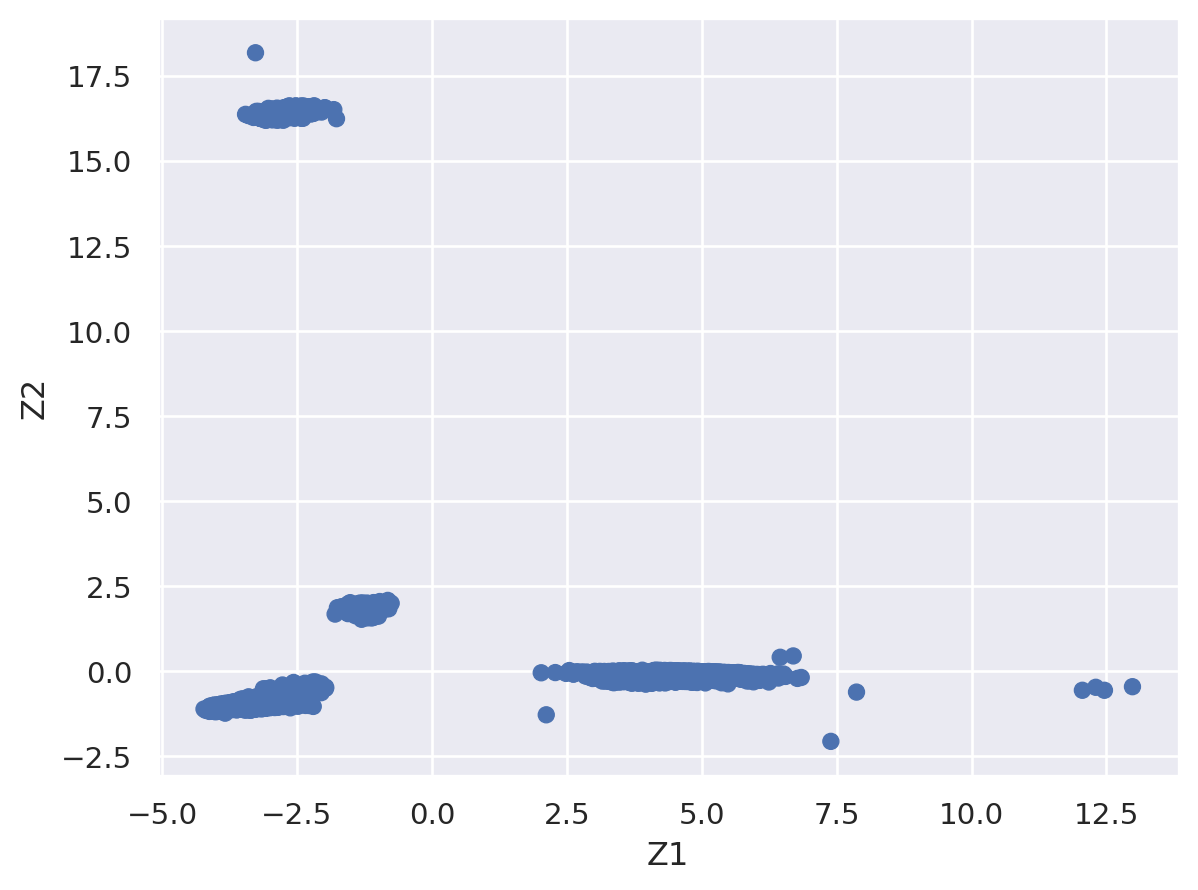

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clustering) #Escalo los datos a media 0 y varianza 1
X_scaled

pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)

# Grafico la proyeccion
(
    so.Plot(x=Z[:,0] , y=Z[:,1])
    .add(so.Dot()).label(x="Z1", y="Z2")
)


Para agrupar los datos utilizamos **K-Means**. El método consiste en agrupar los datos segun la distancia a cada centro de un cluster, posteriormente los centros se mueven al promedio de los grupos creados y se crean nuevos clusters nuevos, este proceso se repite hasta que los elementos no cambie de clusters entre iteracion.

El K-Means minimiza la suma de distancias cuadradas dentro de los clusters.
$$
WCSS = \sum_{i=1}^{k} \sum_{x \in C_i} \|x - \mu_i\|^2
$$

$C_i$ = Cluster\
$μ_i$c= centro del cluster

Si se aumenta K, el error siempre baja, pero llega un punto donde mejorar K no aporta mucho. Ese punto es el "codo", y es el que utilizaremos para determinar K.
\
\
La razón que utilizamos K-Means sobre DBscan es debido a la alta dimensionalidad del problema.

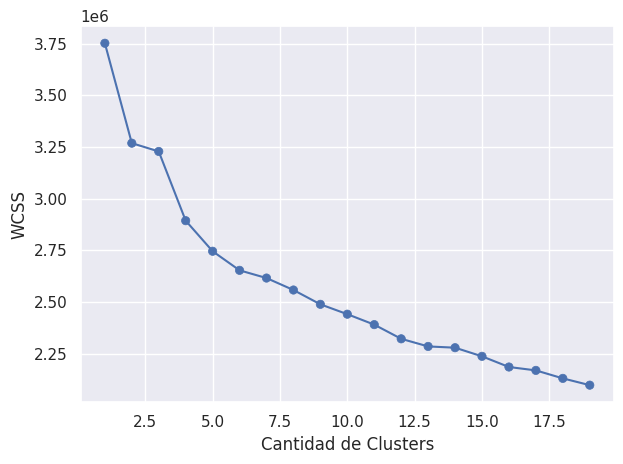

In [13]:
wcss = [] #Para guardar las sumas de distancais cuadradras

for k in range(1,20): #Pruebo distintos cantidad de clusters
    kmeans = cluster.KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)#.Intertia_ me devuelve la suma de distancias cuadradras

so.Plot(x=range(1,20) , y=wcss).add(so.Dot()).add(so.Line()).label(x="Cantidad de Clusters" ,  y="WCSS").show()
etiquetas=cluster.KMeans(n_clusters=4, random_state=0).fit_predict(X_scaled).astype(str)#Eligo 4 por que pareciese ser el ultimo salto fuerte

Luego sobre el grafico de dipersion $Z_1$ vs $Z_2$ vemos si podemos observar los clusters. Para eso, graficaremos de nuevo, pero esta vez coloreando el punto segun el cluster al que pertenece:

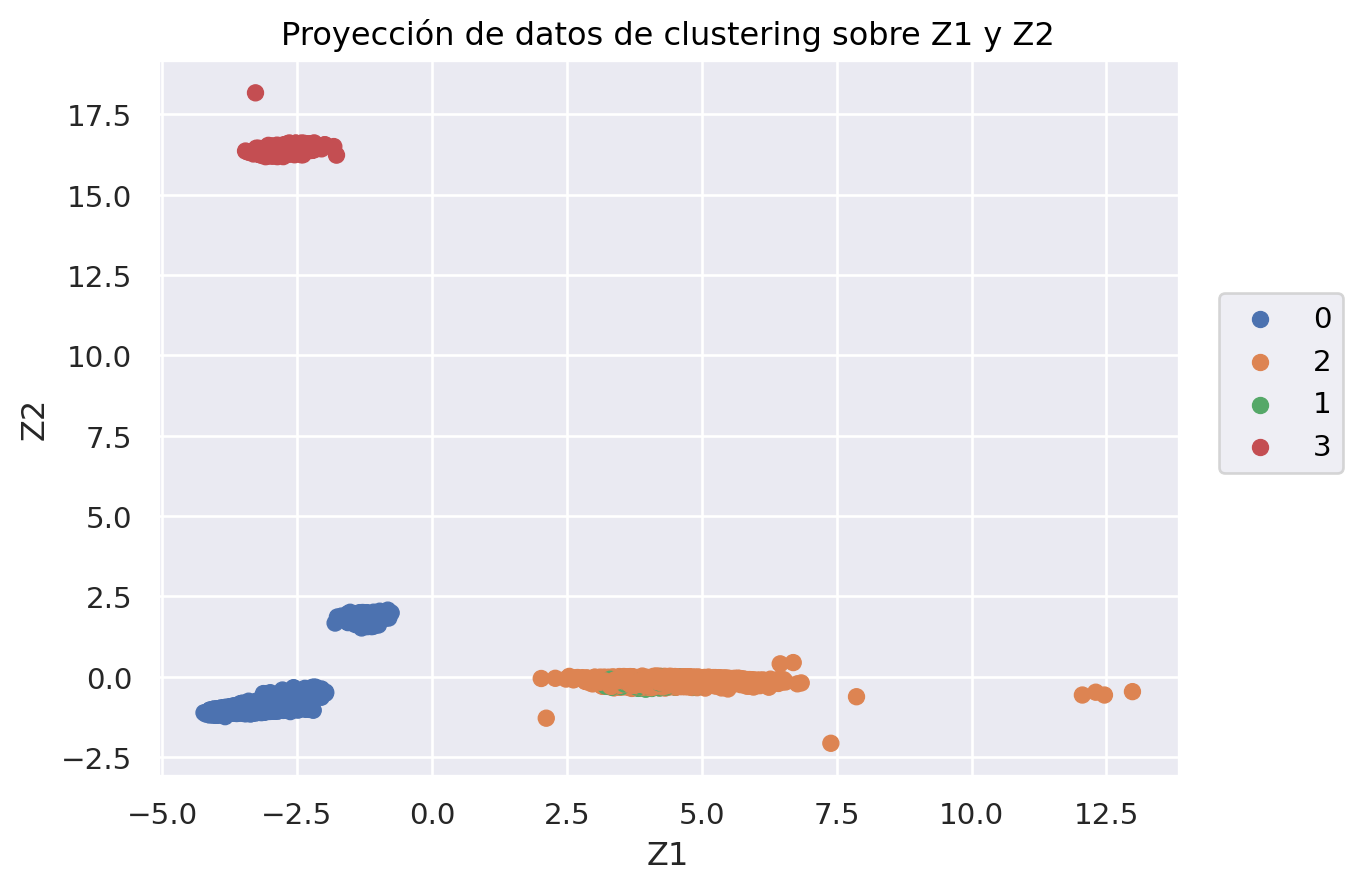

In [14]:
# Realizo el grafico
(
    so.Plot(x=Z[:,0], y=Z[:,1], color=etiquetas)
    .add(so.Dot())
    .label(x="Z1" , y="Z2")
    .label(title="Proyección de datos de clustering sobre Z1 y Z2")
)

No se observan agrupamientos claros para todos los clusters.
Los clusters  0 y 3 parecen tener características tan dominantes que incluso en 2D se mantienen aislados. El resto de los clusters (1 y 2) están solapados, porque la varianza que los diferencia no está contenida en las dos primeras componentes principales.

Por último vamos a observar qué características están presentes en cada cluster observado. Para eso primero veremos los pesos de las componentes principales, ya que $Z_2$ parecie un buen parámetro para separar los cluster, y $Z_1$ es capaz de separar los clusters cuando es negativo:

In [15]:
#La componente Z2 pareciese logar diferenciar bien los clusters 1 y 4
#Busco que variables tienen mas peso positivo en Z2
pesos_pca=pd.DataFrame(pca.components_.T, columns=['Peso_Z1','Peso_Z2'],index=df_clustering.columns) #Guardo las componentes un un Dataframe para poder usar la funcion sort_values y head
print(pesos_pca['Peso_Z2'].sort_values(ascending=False).head(10) ,"\n") #Me permite ordenar de mayor a menor y mostrar solo las 10 primeras


PP02B_1     0.308757
PP02C8_2    0.307265
ESTADO_2    0.302295
PP02C4_2    0.298775
PP02C7_2    0.294221
PP02C5_2    0.288963
PP02C1_2    0.272105
PP02C2_1    0.255274
PP02C3_2    0.248146
PP02C6_2    0.218947
Name: Peso_Z2, dtype: float64 



Observamos que la columna **`PP02B_1`** es la que mayor valor tiene (es decir, la gente que efectivamente está buscando trabajo). Todas las demas variables tienen **`PP02C`** al inicio, que indican la forma en que la persona está buscando empleo. **`ESTADO_2`** es 1 cuando la persona está desocupada. Podemos asumir que el cluster 4 nos agrupa personas en busca de empleo.

In [16]:
#El cluster 1 pareciese separar bien cuando Z1 tiene una fuerte compenente negativa
#Para eso voy a obsercar cuales variables tiene mayor (en valor absoluto) peso negativo.

print(pesos_pca['Peso_Z1'].sort_values(ascending=True).head(10)) #Me permite ordenar de menor a mayor

ESTADO_3     -0.241048
PP02F_2      -0.238536
PP02H_2      -0.238129
PP02I_2      -0.236102
CAT_INAC_3   -0.140292
CAT_INAC_4   -0.080384
CAT_INAC_1   -0.072980
CH07         -0.067810
CH03         -0.065985
CAT_INAC_7   -0.037259
Name: Peso_Z1, dtype: float64


Observamos que la variable con mas peso es **`ESTADO_3`**, que es 1 cuando la persona es jubilada y no está buscando empleo. Esto nos habla de que el cluster 1 es predominado por jubililados. Los clusters son capaces de diferenciar entre personas con empleo, jubilados y personas buscando empleo.

Sabemos que los clusters 1 y 2 corresponden a personas con empleo. Ahora intentamos ver si podemos hallar diferencias entre estos dos clusters. Para eso, vamos a comparar el promedio de cada columna de un cluster contra el promedio global de cada columna del DataFrame. Como queremos saber en qué se diferencia el cluster 1 del cluster 2, veremos cómo son los valores para dichos clusters:

In [17]:
#Diferenciacion Cluster 1 y 2
#Como se comparan los valores promedios del cluster contra el valor global
# 1. Creamos un dataframe que combine los datos originales con la etiqueta del cluster
df_analisis = df_clustering.copy()
df_analisis['cluster'] = etiquetas

# 2. Calculamos el promedio de cada variable para cada cluster
centros = df_analisis.groupby('cluster').mean()

# 3. Calculamos el promedio global del dataset para comparar
promedio_global = df_clustering.mean()

# 4. Buscamos las variables donde un cluster se desvía más del promedio
diferencia_relativa = (centros - promedio_global) / promedio_global

#Quiero comparar el Cluster 1 y 2 entre ellos voy observar donde se presenta la mayor diferencia entre estos
diff_entre_clusters = (diferencia_relativa.iloc[1] - diferencia_relativa.iloc[2]).transpose()
print(diff_entre_clusters.sort_values(ascending=True).head(10),"\n")
print(diff_entre_clusters.sort_values(ascending=False).head(10),"\n")


PP04B3_ANO   -2.438682
PP04A_3.0    -2.438682
PP04G_4.0    -2.438682
PP04G_7.0    -2.438682
PP04G_5.0    -2.438682
PP04G_9.0    -2.438682
PP04G_11.0   -2.438682
PP03D_5.0    -2.438682
PP03H_9.0    -2.438682
PP03D_8.0    -2.438682
dtype: float64 

PP04G_12.0     50.670807
CAT_OCUP_4     10.093532
CAT_OCUP_2      5.081547
SECTOR_2.0      3.603353
PP03J_9.0       2.872267
CAT_OCUP_1      2.430717
PP03H_2.0       1.646664
INTENSI_3.0     1.013636
REGION_41       0.727943
PP04A_2.0       0.668015
dtype: float64 



Hay una fuerte diferencia en las variables que inician con **`PP04G_12`**, que corresponde la gente que trabaja en su casa con lugar exclusivo. Adicionalmente, parece haber diferencia entre el cluster 1 y 2: en primero se concentra gente que trabaja por cuenta propia, como se puede observar en **`CAT_OCUP_2`**.

## Clasificación

En esta sección se buscará predecir si el trabajo que tienen las personas que están empleadas es formal, informal o de servicio doméstico, y analizar qué variables influyen en el tipo de trabajo.

### Inciso 14

En primer lugar, se genera un dataframe **`df_clasificacion`** que contiene sólo a los individuos con valores 1, 2 o 3 en la columna **`SECTOR`** (que indica el sector ocupacional: 1 para el Formal, 2 para el Informal, 3 para el Doméstico (Hogares), 9 para quienes no saben o no respondieron, y 0 donde solía haber $\texttt{NaNs}$):

In [18]:
df_clasificacion = df_clean[df_clean["SECTOR"].isin([1, 2, 3])]

print("Valores que quedaron en la columna 'SECTOR':", df_clasificacion["SECTOR"].unique())

Valores que quedaron en la columna 'SECTOR': [2. 1. 3.]


### Inciso 15

Se elimina a los individuos (las filas) con ingreso total (columna **`P47T`**) de valor 0, y luego se reemplazan los valores de esta columna por sus logaritmos naturales:

In [19]:
# Se dejan sólo las filas con valores distintos a 0 en la columna
# "P47T":
df_clasificacion = df_clasificacion[df_clasificacion["P47T"] != 0]

# Luego, se usa la función "log" de NumPy para tomar el logaritmo
# natural de los valores en la columna "P47T" y reasignárselos a
# ella:
df_clasificacion["P47T"] = np.log(df_clasificacion["P47T"])

display(df_clasificacion["P47T"]) # Para observar cómo quedaron los valores.

1        12.899220
4        13.997832
9        13.122363
10       13.742940
12       14.914123
           ...    
32623    12.765688
32626    13.102161
32629    14.130321
32630    13.458836
32631    14.457364
Name: P47T, Length: 13517, dtype: float64

Ahora que ya se dispone de todos los datos necesarios para realizar clasificación (con valores adecuados), se procede a normalizar (ubicar en el rango [0,1]) a los valores de las columnas:

In [20]:
# Se utiliza el MinMaxScaler para normalizar, ya que deja a todos los
# valores en las columnas dentro del rango [0,1], donde 0 se asigna
# al mínimo y 1 al máximo:
scaler = MinMaxScaler()

# Se escalan los datos de clasificación:
df_clasificacion_norm = scaler.fit_transform(df_clasificacion)

# display(df_clasificacion_norm) # Para observar la normalización.

Luego, mediante PCA (*Principal Component Analysis*) se calculan las dos primeras componentes principales, $Z_1$ y $Z_2$ (las dos que más varianza explican de los datos) y se realiza un gráfico de dispersión de la proyección de los datos originales sobre ellas, coloreando los puntos según el valor de la columna **`SECTOR`**:

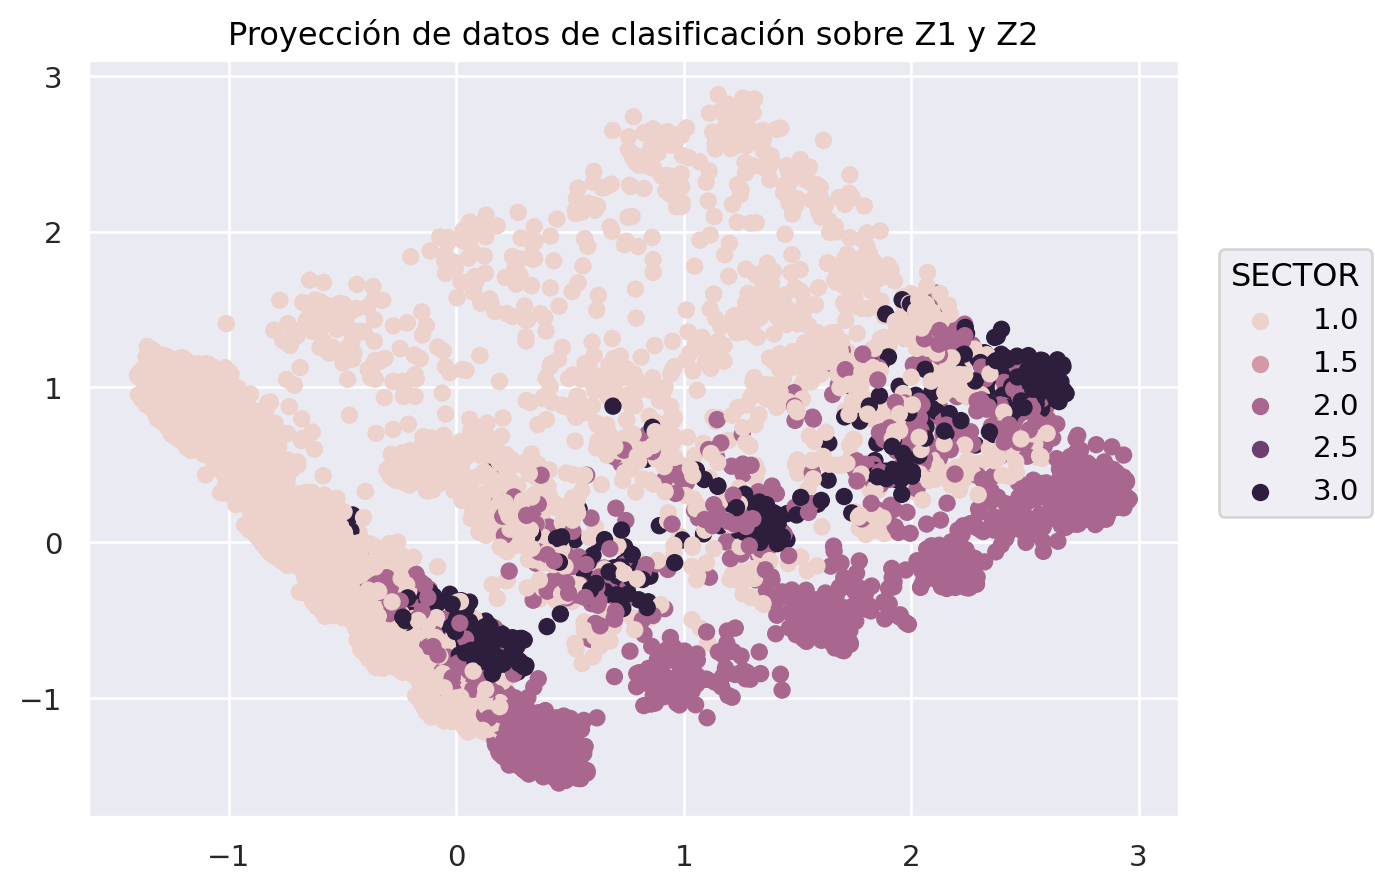

In [21]:
pca = PCA(n_components=2)
df_clasificacion_proy = pca.fit_transform(df_clasificacion_norm)

# Se grafica la proyección de los datos de clasificación sobre
# las dos primeras componentes principales:
(
    so.Plot(x=df_clasificacion_proy[:,0],
            y=df_clasificacion_proy[:,1],
            color=df_clasificacion["SECTOR"])
    .add(so.Dot())
    .label(title="Proyección de datos de clasificación sobre Z1 y Z2")
)

Notar que  los datos aparecen en tres "nubes" más o menos distinguibles, identificables en el eje de las ordenadas con la primera nube en los puntos más arriba, los de la segunda nube al medio, y los de la tercera abajo.

Finalmente, se desarrolla un modelo de clasificación utilizando el algoritmo **kNN** (*k-Nearest Neighbors*) para el valor en la variable **`SECTOR`** (1 para el Formal, 2 para el Informal, 3 para el Doméstico (Hogares)) de los individuos (filas). Para ello se utilizará un 80% de los datos originales para entrenamiento, y el 20% restante para testeo:

In [22]:
X = df_clasificacion.loc[:, df_clasificacion.columns != "SECTOR"]
y = df_clasificacion["SECTOR"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Una vez definidos los conjuntos de entrenamiento y testeo, se normalizan las variables (columnas) en el conjunto de entrenamiento:

In [23]:
scaler = MinMaxScaler()

# Se ajusta el scaler con X_train y luego se aplica el
# escalamiento (normalización) sobre este último:
X_scaled = scaler.fit_transform(X_train)
# Nota: este scaler se usará en el futuro para escalar
# los datos de testeo de la misma forma que los datos de
# entrenamiento.

Finalmente, con los datos escalados, se busca el mejor hiperparámetro $k$ para los modelos que usan **kNN**, usando *accuracy* como métrica a optimizar:

In [24]:
param_grid  = {
    "n_neighbors" : np.arange(1,20), # Rango de valores para k: 1 a 19.
}

# Se define el algoritmo con el que modelar (kNN):
knn = KNeighborsClassifier()

# Se define una búsqueda usando 5-Fold Cross-Validation para
# los valores 1 a 19 del hiperparámetro k de kNN, buscando
# oprimizar la métrica "accuracy":
clf = GridSearchCV(
    estimator=knn, # Se usa estimador kNN.
    param_grid=param_grid, # Se le pasa el rango de k.
    cv=5, # Se usa K-Fold Cross-Validation con K = 5 folds.
    scoring="accuracy", # Usa accuracy para elegir el mejor.
    n_jobs=-1 # Usa todos los cores del procesador en paralelo.
)

# Se ejecuta la búsqueda sobre el conjunto de entrenamiento:
clf.fit(X_scaled, y_train)

# Se muestra el mejor hiperparámetro y la mejor accuracy obtenidos:
print("Mejores parámetros:      ", clf.best_params_)
print("Mejor accuracy obtenida: ", clf.best_score_)

Mejores parámetros:       {'n_neighbors': 10}
Mejor accuracy obtenida:  0.9349853712444984


Habiendo obtenido la mejor *accuracy* con *k* = 10, se la calcula sobre el conjunto de entrenamiento, para evaluar cuán bueno sería este modelo sobre datos nuevos (normalizándolos primero como a los datos de entrenamiento):

In [25]:
print(
    "Accuracy del mejor modelo sobre el conjunto de testeo: ",
    clf.best_estimator_.score(scaler.transform(X_test), y_test)
)

Accuracy del mejor modelo sobre el conjunto de testeo:  0.9393491124260355


Como el modelo utiliza un dataset con muchas variables, resultaría interesante analizar si sería posible realizar una buena clasificación (usando kNN) con una menor cantidad.

A priori, si se deseara dejar una cantidad mínima de variables, se podrían elegir sólo tres: **`EMPLEO`**, **`P47T`**, y **`NIVEL_ED`**. La resulta claramente útil porque ya proporciona información de empleo (1 si es Formal, 2 si es Informal, 9 si no sabe o no responde), mientras que la segunda (los ingresos totales) podría ser útil ya que se espera que los trabajos informales y domésticos, al ser potencialmente de mayor precariedad, podrían estar asociados a ingresos totales más bajos. La última variable, que indica el nivel educativo, también se espera que sea relevante, dado que se sospecha que los trabajos formales suelen requerir mayor capacitación formal (usualmente impartida en instituciones educativas). A continuación se pone a prueba un modelo usando kNN que sólo utiliza las variables mencionadas:

In [26]:
# Se juntan todas las columnas que empiecen con los nombres
# originales de las columnas que se desea usar (en caso que
# hayan sido modificadas por haber sido transformadas en dummies):
columnas_clasificacion_reducida = [
    col for col in df_clasificacion.columns if
        col.startswith("EMPLEO") or
        col.startswith("P47T") or
        col.startswith("NIVEL_ED")
]

# Se vuelve a separar al dataset en un conjunto de entrenamiento
# (80%) y otro de testeo (20%):
X = df_clasificacion[columnas_clasificacion_reducida]
y = df_clasificacion["SECTOR"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Se define un modelo kNN "óptimo" usando el valor del
# mejor hiperpárametro k hallado previamente:
knn_optimo = KNeighborsClassifier(n_neighbors=10)

# Se ajusta el modelo kNN "óptimo" a los datos de
# entrenamiento y luego se realiza la predicción
# para los datos de testeo, normalizando adecuadamente:
X_scaled = scaler.fit_transform(X_train)
knn_optimo.fit(X_scaled, y_train)

print(
    "Accuracy sobre los datos de testeo usando sólo las columnas",
    columnas_clasificacion_reducida, ": ",
    knn_optimo.score(scaler.transform(X_test), y_test)
)

Accuracy sobre los datos de testeo usando sólo las columnas ['NIVEL_ED', 'P47T', 'EMPLEO'] :  0.7869822485207101


Notar que la *accuracy* para este modelo reducido no es mala: clasifica acertadamente a 3 de cada 4 individuos (de los datos nuevos), aproximadamente. Esto parece ser una fuerte indicación de que estas variables son bastante importantes, y tienen un alto poder predictivo. Otra forma de determinar su importancia es evaluando qué ocurre con la calidad de la clasificación en datos nuevos si se las excluye del dataset:

In [27]:
# Se juntan todas las columnas que no empiecen con los nombres
# originales de las columnas que se desea usar (excluyendo
# también a la columna "index"):
columnas_clasificacion_complementaria = [
    col for col in df_clasificacion.columns if
        not (col in columnas_clasificacion_reducida) and
        not col == "index"
]

# Se vuelve a separar al dataset en un conjunto de entrenamiento
# (80%) y otro de testeo (20%):
X = df_clasificacion[columnas_clasificacion_complementaria]
y = df_clasificacion["SECTOR"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Se ajusta el modelo kNN "óptimo" a los datos de
# entrenamiento y luego se realiza la predicción
# para los datos de testeo, normalizando adecuadamente:
X_scaled = scaler.fit_transform(X_train)
knn_optimo.fit(X_scaled, y_train)

print(
    "Accuracy sobre los datos de testeo excluyendo las columnas",
    columnas_clasificacion_reducida, ": ",
    knn_optimo.score(scaler.transform(X_test), y_test)
)

Accuracy sobre los datos de testeo excluyendo las columnas ['NIVEL_ED', 'P47T', 'EMPLEO'] :  0.9297337278106509


Se puede observar que, a pesar de que las variables elegidas tienen de por sí un poder predictivo razonable, no son lo suficientemente valiosas como para impactar significativamente en el desempeño de un modelo que usa al resto. Esto, sin embargo, no debería ser particularmente inesperado, dado que hay muchas otras variables que no son las tres elegidas (siendo muchas de ellas similarmente informativas), de modo que es de esperar que el desempeño del modelo, en general, no sufra mucho al excluirlas.

## Regresión

En esta sección se buscará predecir el sueldo de las personas ocupadas mediante distintos modelos de regresión.

Nos gerenamos un dataframe **`df_regresion`** que contenga sólo las personas ocupadas, con ingreso total positivo:

In [28]:
columnas_estado = [c for c in df_clean.columns if "ESTADO" in c]

es_ocupado = (df_clean[columnas_estado].sum(axis=1) == 0)

df_regresion = df_clean[es_ocupado & (df_clean['P47T'] > 0)].copy()

Vamos a trabajar con el logaritmo de la variable **`P47T`**. Para eso, tomamos el logaritmo utilizando la funcion $\texttt{log}$ de NumPy:

In [29]:
df_regresion['P47T'] = np.log(df_regresion['P47T'])

Intentamos ajustar la variable **`P47T`** mediante modelos distintos: una regresión lineal ordinaria, una regresión Ridge, y por último utilizaremos una red neuronal.
El DataFrame fue dividido en un conjunto de entrenamiento y un conjunto de testeo en el que haremos predicciones para observar el rendimiento de los modelos.

#### Modelo 1
Como primer paso para analizar los ingresos, el Modelo 1 fue una regresión lineal múltiple usando todas las variables disponibles. Esto incluyó datos personales como edad, sexo y nivel educativo, junto con la región donde vive la persona. Este modelo nos sirve como punto de partida y logró un $R^2$ de 0.4746 en los datos de prueba. Esto significa que estas características logran explicar el 47.5% de las diferencias en los sueldos, lo que nos da una buena base para comparar con los otros modelos.

In [30]:
y = df_regresion['P47T']
X = df_regresion.drop(columns=['P47T'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
print(f"R2 Lineal: {modelo.score(X_test, y_test):.4f}")

R2 Lineal: 0.4908


#### Modelo 2
El Modelo 2 fue una regresión Ridge. Usamos este modelo para asegurarnos de que ninguna variable tenga un peso exagerado en el cálculo final. Para armarlo, hicimos que el código pruebe varios valores y se quede automáticamente con el que mejor funciona. El puntaje final que nos dio fue prácticamente el mismo que el del primer modelo. Con esto comprobamos que nuestra base de datos está equilibrada, y que la regresión lineal simple ya estaba haciendo un buen trabajo desde el principio.

Mejor valor de Alpha encontrado: 10
R2 Ridge optimizado: 0.4912


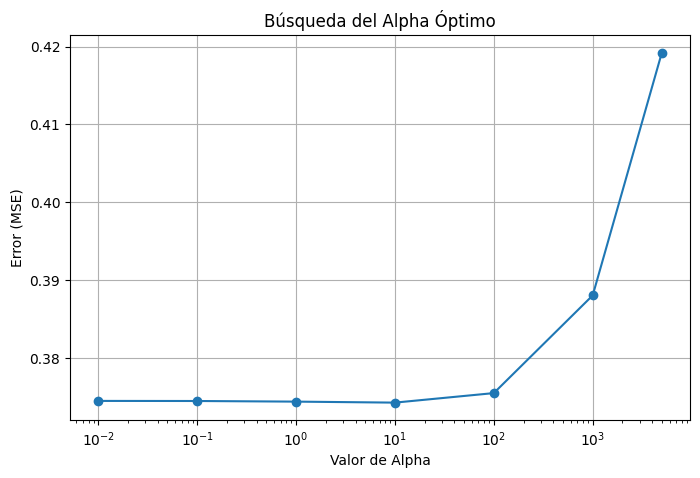

In [31]:
parametros_ridge = {'alpha': [0.01, 0.1, 1, 10, 100, 1000, 5000]}

grid_ridge = GridSearchCV(Ridge(), parametros_ridge, cv=5, scoring='neg_mean_squared_error')
grid_ridge.fit(X_train, y_train)

best_ridge = grid_ridge.best_estimator_

print(f"Mejor valor de Alpha encontrado: {grid_ridge.best_params_['alpha']}")
print(f"R2 Ridge optimizado: {best_ridge.score(X_test, y_test):.4f}")

scores = grid_ridge.cv_results_['mean_test_score']
alfas_probados = parametros_ridge['alpha']

plt.figure(figsize=(8, 5))
plt.plot(alfas_probados, -scores, marker='o')
plt.xscale('log')
plt.xlabel('Valor de Alpha')
plt.ylabel('Error (MSE)')
plt.title('Búsqueda del Alpha Óptimo')
plt.grid(True)
plt.show()



El gráfico de la Curva de Validación permite analizar cómo varía el Error Cuadrático Medio (MSE) en función de la intensidad de la regularización aplicada al modelo Ridge:
    
* **Identificación del punto óptimo**: Se observa que el error mínimo en el conjunto de validación se alcanza con un α=10. Este valor coincide con el resultado obtenido mediante el proceso de GridSearchCV, confirmando que es la configuración que mejor balancea la precisión y la estabilidad del modelo.
  
* **Análisis de subajuste (Underfitting)**: Para valores de α superiores a 100, el error se incrementa de forma marcada. Esto indica que una penalización demasiado alta simplifica excesivamente el modelo, provocando que pierda capacidad para capturar las relaciones entre las variables predictoras y el ingreso laboral.
  
* **Balance sesgo-varianza**: La elección de α=10 permite reducir la varianza del modelo sin introducir un sesgo significativo. Al limitar la magnitud de los coeficientes, el modelo se vuelve menos sensible al ruido de los datos de entrenamiento y mejora su capacidad de generalización frente a nuevos registros de la encuesta

#### Modelo 3

Se propone una red neuronal básica: un **MLP** (*MultiLayer Perceptron* o *Perceptrón Multicapa*) que se entrena de forma simple, sobre un 80% de entrenamiento y 20% de testeo en cada epoch, usando MSE como función de pérdida (y reportando el RMSE al final de cada *epoch*). El MLP está compuesto por dos capas internas que van decrementando su cantidad de neuronas por la mitad, partiendo de la cantidad de features capa de entrada, y usando como a la ReLU como función de activación.

In [32]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold

torch.manual_seed(42)
torch.use_deterministic_algorithms(True)

# Se asigna el modelo para entrenar en CPU o GPU (CUDA):
device = torch.device("cpu")# if torch.cuda.is_available() else "cpu")

num_features = X_train.shape[1]

# Se propone un MLP (MultiLayer Perceptron) básico:
mlp = nn.Sequential(
    nn.Linear(num_features, num_features // 2),
    nn.ReLU(),
    nn.Linear(num_features // 2, num_features // 4),
    nn.ReLU(),
    nn.Linear(num_features // 4, 1)
).to(device)

# Se transforma los datos a tensores de pytorch (podrían escalarse
# antes):
X_train_t = torch.from_numpy(X_train.to_numpy()).float()
y_train_t = torch.from_numpy(y_train.to_numpy()).float()
X_test_t = torch.from_numpy(X_test.to_numpy()).float()
y_test_t = torch.from_numpy(y_test.to_numpy()).float()

# Se define el batch_size (cada cuántos datos se ajustan los pesos
# del MLP), los datasets y dataloaders (para train y test):
batch_size = X_train.shape[0] // 100
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset  = TensorDataset(X_test_t, y_test_t)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_dataloader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

# Se define el learning rate, el tipo de optimizador (controla cómo
# progresa el descenso por gradiente) y la función de pérdida (MSE,
# porque la estimación es una regresión):
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-5)
criterion = torch.nn.MSELoss()

# Ciclo de entrenamiento:
epochs = 20

train_losses, test_losses = [], []
for e in range(epochs):
    tot_train_loss = 0
    for features, targets in train_dataloader:
        features, targets = features.to(device), targets.to(device)
        optimizer.zero_grad()

        loss = criterion(mlp(features), targets)
        tot_train_loss += loss.item()

        loss.backward()
        optimizer.step()
    else:
        tot_test_loss = 0

        # Deshabilita gradientes para testeo, para ahorrar memoria y cómputos:
        with torch.no_grad():
            for features, targets in test_dataloader:
                feature, targets = features.to(device), targets.to(device)
                loss = criterion(mlp(features), targets)
                tot_test_loss += loss.item()

        # Calcula loss promedio para comparar entre conjuntos de entrenamiento y testeo:
        train_loss = tot_train_loss / len(train_dataloader.dataset)
        test_loss = tot_test_loss / len(test_dataloader.dataset)

        # Al completarse un epoch:
        train_losses.append(train_loss)
        test_losses.append(test_loss)

        print(
            "Epoch: {}/{}.. ".format(e+1, epochs),
            "Loss Entrenamiento: {:.3f}.. ".format(np.sqrt(train_loss)),
            "Loss Testeo: {:.3f}.. ".format(np.sqrt(test_loss)) # Se toma raíz cuadrada por ser loss = MSE.
        )

/home/kaneda/.virtualenvs/rn/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([110])) that is different to the input size (torch.Size([110, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/kaneda/.virtualenvs/rn/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([84])) that is different to the input size (torch.Size([84, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/kaneda/.virtualenvs/rn/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([22])) that is different to the input size (torch.Size([22, 1])). This will likely lead to incorrect results due to broadcasting. Please en

Epoch: 1/20..  Loss Entrenamiento: 6.278..  Loss Testeo: 4.503.. 
Epoch: 2/20..  Loss Entrenamiento: 3.247..  Loss Testeo: 2.105.. 
Epoch: 3/20..  Loss Entrenamiento: 1.461..  Loss Testeo: 0.967.. 
Epoch: 4/20..  Loss Entrenamiento: 0.774..  Loss Testeo: 0.691.. 
Epoch: 5/20..  Loss Entrenamiento: 0.658..  Loss Testeo: 0.664.. 
Epoch: 6/20..  Loss Entrenamiento: 0.649..  Loss Testeo: 0.663.. 
Epoch: 7/20..  Loss Entrenamiento: 0.648..  Loss Testeo: 0.662.. 
Epoch: 8/20..  Loss Entrenamiento: 0.648..  Loss Testeo: 0.662.. 
Epoch: 9/20..  Loss Entrenamiento: 0.647..  Loss Testeo: 0.661.. 
Epoch: 10/20..  Loss Entrenamiento: 0.645..  Loss Testeo: 0.650.. 
Epoch: 11/20..  Loss Entrenamiento: 0.635..  Loss Testeo: 0.648.. 
Epoch: 12/20..  Loss Entrenamiento: 0.633..  Loss Testeo: 0.646.. 
Epoch: 13/20..  Loss Entrenamiento: 0.628..  Loss Testeo: 0.635.. 
Epoch: 14/20..  Loss Entrenamiento: 0.620..  Loss Testeo: 0.632.. 
Epoch: 15/20..  Loss Entrenamiento: 0.618..  Loss Testeo: 0.630.. 
Epoc

Para comparar modelos mediremos el RMSE entre las predicciones del modelo y los valores observados en el conjunto de testeo, quedándonos con el que posea menor RMSE:

In [33]:
def calcular_rmse(modelo, X, y):
    predicciones = modelo.predict(X)
    mse = mean_squared_error(y, predicciones)
    return np.sqrt(mse)

rmse_lineal = calcular_rmse(modelo, X_test, y_test)
rmse_ridge  = calcular_rmse(best_ridge, X_test, y_test)
rmse_mlp    = np.sqrt(test_loss)

print(f"RMSE Regresión Lineal : {rmse_lineal:.4f}")
print(f"RMSE Ridge (Alpha=10): {rmse_ridge:.4f}")
print(f"RMSE MLP (MultiLayer Perceptron): {rmse_mlp}")

if rmse_ridge < rmse_lineal and rmse_ridge < rmse_mlp:
    ganador = "Ridge"
    rmse_final = rmse_ridge
elif rmse_mlp < rmse_lineal and rmse_mlp < rmse_ridge:
    ganador = "MLP"
    rmse_final = rmse_mlp
else:
    ganador = "Lineal"
    rmse_final = rmse_lineal

print(f"\n EL MEJOR MODELO ES: {ganador}")
print(f" RMSE EN TESTEO: {rmse_final:.4f}")

RMSE Regresión Lineal : 0.5927
RMSE Ridge (Alpha=10): 0.5925
RMSE MLP (MultiLayer Perceptron): 0.6128424231159495

 EL MEJOR MODELO ES: Ridge
 RMSE EN TESTEO: 0.5925


Observar que la red neuronal (el MLP), a pesar de ser el modelo más "pesado" (con más parámetros), no es el mejor. Esto evidencia cómo no alcanza con simplemente hacer más complejo un modelo, sino que hace falta explorar inteligentemente el espacio de parámetros (e hiperpárametros) para que se pueda explotar el potencial desempeño de un modelo al máximo.

Por último, queremos observar cómo influyen tres variables en los ingresos de una persona. Las tres variables a utilizar serán **`CH04`** (el sexo), **`NIVEL_ED`** (el nivel educativo) y **`REGION`** (la región en la que trabaja):

In [34]:
df_coef = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': best_ridge.coef_
}).sort_values(by='Coeficiente', ascending=False)

variables_analisis = ['NIVEL_ED', 'CH04', 'REGION']
resultados = df_coef[df_coef['Variable'].str.contains('|'.join(variables_analisis))]

print("Coeficientes de las variables seleccionadas:")
print(resultados)

perfil_test = X_test.iloc[0:1].copy()

perfil_test['NIVEL_ED'] = 4
for col in X.columns:
    if 'REGION' in col:
        perfil_test[col] = 0
perfil_test['REGION_44'] = 1 # Código para la Patagonia

sujeto_varon = perfil_test.copy()
sujeto_varon['CH04'] = 1 # Código INDEC para Varón

sujeto_mujer = perfil_test.copy()
sujeto_mujer['CH04'] = 2 # Código INDEC para Mujer

log_ingreso_v = best_ridge.predict(sujeto_varon)[0]
log_ingreso_m = best_ridge.predict(sujeto_mujer)[0]

ingreso_v = np.exp(log_ingreso_v)
ingreso_m = np.exp(log_ingreso_m)

print("\n--- Resultado del Experimento ---")
print(f"Ingreso estimado para Varón (mismas condiciones): ${ingreso_v:.2f}")
print(f"Ingreso estimado para Mujer (mismas condiciones): ${ingreso_m:.2f}")
print(f"Diferencia porcentual estimada: {((ingreso_m / ingreso_v) - 1) * 100:.2f}%")

Coeficientes de las variables seleccionadas:
     Variable  Coeficiente
22  REGION_44     0.234329
7    NIVEL_ED     0.105872
21  REGION_43     0.002629
1        CH04    -0.120305
20  REGION_42    -0.146323
19  REGION_41    -0.164388
18  REGION_40    -0.177426

--- Resultado del Experimento ---
Ingreso estimado para Varón (mismas condiciones): $714650.50
Ingreso estimado para Mujer (mismas condiciones): $633644.87
Diferencia porcentual estimada: -11.33%


En esta subsección buscamos interpretar el sentido de los coeficientes del modelo Ridge. Elegimos las variables Nivel Educativo (**`NIVEL_ED`**), Sexo (**`CH04`**) y Región (**`REGION`**) debido a que presentan una alta relevancia teórica para explicar la desigualdad de ingresos.

Por qué este análisis es importante para el trabajo:


*   **Aislamiento de variables:** Al usar el método *ceteris paribus*, eliminamos la duda de si la diferencia es por educación o por zona geográfica. Al ser perfiles idénticos, la diferencia de ingresos que ves en el gráfico es el impacto "puro" de la variable de género según el modelo.
*   **Validación regional:** El coeficiente de la **Región 44** (Patagonia) es de **$0.232999$**. Esto indica que, a igualdad de condiciones, vivir en el sur implica un aumento del **26.24**% en el ingreso estimado respecto a la región base, validando la calidad de la predicción y el costo de vida de la zona
* **Retorno educativo:** El coeficiente de **$0.116816$** para **`NIVEL_ED`** significa que cada nivel extra de educación le suma aproximadamente un **12.39%** al sueldo. Es una medida técnica de cuánto 'paga' el mercado por la formación académica.
* **La Brecha de Género:** El impacto del género muestra un coeficiente de $-0.135918$. Esto se traduce en que, bajo las mismas condiciones de edad y educación, las mujeres perciben un **12.71%** menos que los varones. (Se probee un grafico de esta esta brecha)

Para poner a prueba el peso de las variables que venimos estudiando, armamos un modelo complementario donde eliminamos el nivel educativo, el género y la residencia en la Patagonia:

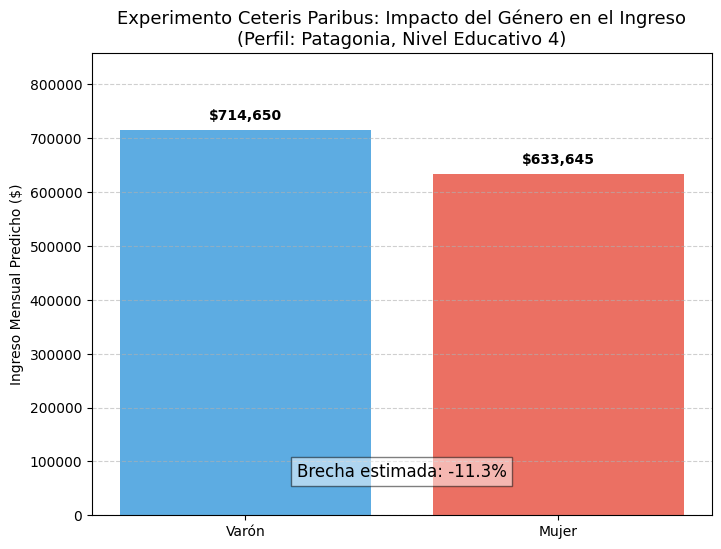

In [35]:
categorias = ['Varón', 'Mujer']
predicciones = [ingreso_v, ingreso_m]
colores = ['#3498db', '#e74c3c']

plt.figure(figsize=(8, 6))
barras = plt.bar(categorias, predicciones, color=colores, alpha=0.8)

for barra in barras:
    alto = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, alto + (alto * 0.02),
             f'${alto:,.0f}', ha='center', va='bottom', fontweight='bold')

plt.title('Experimento Ceteris Paribus: Impacto del Género en el Ingreso\n(Perfil: Patagonia, Nivel Educativo 4)', fontsize=13)
plt.ylabel('Ingreso Mensual Predicho ($)')
plt.ylim(0, max(predicciones) * 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.6)

brecha = ((ingreso_m / ingreso_v) - 1) * 100
plt.text(0.5, max(predicciones) * 0.1, f'Brecha estimada: {brecha:.1f}%',
         ha='center', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

plt.show()

In [36]:
columnas_a_borrar = ['NIVEL_ED', 'CH04', 'REGION_44']

X_complementario = X.drop(columns=columnas_a_borrar)

X_train_rev, X_test_rev, y_train_rev, y_test_rev = train_test_split(X_complementario, y, test_size=0.2, random_state=42)

modelo_complementario = LinearRegression()
modelo_complementario.fit(X_train_rev, y_train_rev)

print("--- EXPERIMENTO COMPLEMENTARIO ---")
print(f"R2 del Modelo Completo: {modelo.score(X_test, y_test):.4f}")
print(f"R2 sin Educación, Género ni Patagonia: {modelo_complementario.score(X_test_rev, y_test_rev):.4f}")

--- EXPERIMENTO COMPLEMENTARIO ---
R2 del Modelo Completo: 0.4908
R2 sin Educación, Género ni Patagonia: 0.4600


Sorprendentemente, el puntaje $R^2$ del modelo bajó muy poco, pasando de 0.4746 a 0.4454. Este resultado nos demuestra algo clave: si bien sabemos que estas tres características generan diferencias importantes en casos individuales, la poca caída en el puntaje general sugiere que existen otros factores en nuestra base de datos (posiblemente la edad o las horas trabajadas) que tienen un peso lo suficientemente grande como para sostener la predicción de los sueldos de toda la población.